# Evaluation of the Final Model
Notebook 02 froze the final model (XGBoost, trained on Base months 0-3 with 5 seeds, thresholds picked on month 5) and reported its test results on months 6-7 of Base and the 5 variants. This notebook looks at those results more closely: how sure we can be of them, and how they change from month to month.

**Nothing is retrained or re-tuned here.** The frozen model in `outputs/models/` and `configs/final_model.json` is only used to score applications, so nothing in this notebook can steer the model.

Outline:
1. Imports
2. Setup: months, seeds, functions copied from notebook 02, the frozen models
3. Score everything once (saved to a cache), and check the scores
4. Test results over 5 seeds
5. Bootstrap 95% confidence intervals
6. Performance by month
7. Calibration: turning scores into probabilities (to come)
8. Different fraud rates (to come)
9. Cost-based thresholds (to come)
10. Shifting fraud rates: which threshold rule holds up (to come)
11. Drift over time (to come)
12. Customer groups (to come)
13. Summary (to come)

## **1. Imports**

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score

from model_loading import load_model   # works on Windows too (see README, Prerequisites)

# Plot settings (same as notebooks 02 and 03)
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Setup**
The same evaluation rules as notebook 02:

| Months | Used for |
|---|---|
| 0-3 | training the models |
| 4 | comparing models and tuning (validation) |
| 5 | picking the threshold for the final model |
| 6-7 | final results, on Base and on all 5 variants |

Base is scored on every month (0-7), so we can see how the model behaves on the months it was trained on as well as on later ones. The variants are scored on months 5-7 only: the model never saw any variant, so months 0-4 of a variant would add little.

In [2]:
DATA_DIR = '../data'
CACHE_FILE = f'{DATA_DIR}/cache/scores.parquet'   # data/ is not committed, so neither is the cache
DATASET_FILES = {
    'base': 'Base.csv',
    'variant_i': 'Variant I.csv',
    'variant_ii': 'Variant II.csv',
    'variant_iii': 'Variant III.csv',
    'variant_iv': 'Variant IV.csv',
    'variant_v': 'Variant V.csv',
}
DATASETS = list(DATASET_FILES)
TARGET = 'fraud_bool'

TRAIN_MONTHS = [0, 1, 2, 3]
VALIDATION_MONTHS = [4]
CALIBRATION_MONTHS = [5]
TEST_MONTHS = [6, 7]
BASE_MONTHS = list(range(8))   # Base is scored on every month
VARIANT_MONTHS = [5, 6, 7]     # the variants on the threshold month and the test months

SEEDS = [0, 1, 2, 3, 4]
TARGET_FPR = 0.05   # at most 5% of genuine applications may be flagged

### **2.1 Functions Copied from Notebook 02**
The metric, the features and the test results are computed exactly as in notebook 02. The functions below are **copies** of notebook 02 (sections 2, 3, 4.2 and 8); if those change, update them here too.

In [3]:
def recall_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Copied from notebook 02, section 2."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1   # last point still within the budget
    return tpr[i]


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    """Copied from notebook 02, section 2."""
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1
    return thresholds[i]

In [4]:
MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']


def preprocess(df, missing_flags=True):
    """Copied from notebook 02, section 3."""
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    """Copied from notebook 02, section 4.2."""
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])

In [5]:
def evaluate(y_true, scores, threshold, ages):
    """Copied from notebook 02, section 8."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    flagged = scores >= threshold
    fraud = y_true == 1
    genuine = y_true == 0
    is_50_plus = np.asarray(ages) >= 50

    fpr_50_plus = flagged[genuine & is_50_plus].mean()
    fpr_under_50 = flagged[genuine & ~is_50_plus].mean()

    return {
        'recall@5%FPR': recall_at_fpr(y_true, scores),
        'ROC-AUC': roc_auc_score(y_true, scores),
        'PR-AUC': average_precision_score(y_true, scores),
        'recall at threshold': flagged[fraud].mean(),
        'FPR at threshold': flagged[genuine].mean(),
        'precision at threshold': y_true[flagged].mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }


METRICS = ['recall@5%FPR', 'ROC-AUC', 'PR-AUC', 'recall at threshold', 'FPR at threshold',
           'precision at threshold', 'FPR 50+', 'FPR under 50', 'predictive equality']

### **2.2 The Frozen Models**
The 5 trained models (one per seed) and their month-5 thresholds, loaded with `load_model` (plain `joblib.load` fails on Windows).

In [6]:
final_model = json.load(open('../configs/final_model.json'))
FEATURES = final_model['features']
thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}
models = {seed: load_model(f"../outputs/models/{final_model['model']}_seed{seed}.joblib") for seed in SEEDS}

print('Model:', final_model['model'], '| features:', FEATURES)
pd.Series(thresholds, name='threshold (month 5)').rename_axis('seed').to_frame()

Model: xgboost | features: {'missing_flags': True, 'drifting': 'ratio', 'valid_phones': False, 'include_age': True}


,threshold (month 5)
seed,
0,0.474851
1,0.473538
2,0.477038
3,0.476572
4,0.473818


## **3. Score Everything Once**
Every later section works from one table of scores: Base months 0-7 and every variant's months 5-7, with all 5 seeds. Scoring takes about a minute, so the table is saved to `data/cache/scores.parquet` and loaded from there on later runs. Delete the file to score again.

Besides the scores, the table keeps the label, the month, the row number in the original CSV (`row_id`, as in `outputs/predictions/`) and a few applicant columns for later sections.

In [7]:
KEEP_COLUMNS = ['customer_age', 'income', 'employment_status', 'housing_status', 'source',
                'device_os', 'payment_type']


def score_dataset(dataset, months):
    """Scores the given months of one dataset with all 5 frozen models."""
    df = pd.read_csv(f'{DATA_DIR}/{DATASET_FILES[dataset]}')
    part = df[df['month'].isin(months)]
    X = make_features(part, **FEATURES)

    table = pd.DataFrame({
        'dataset': dataset,
        'row_id': part.index.to_numpy(),
        'month': part['month'].to_numpy(),
        'y_true': part[TARGET].to_numpy(),
    })
    for col in KEEP_COLUMNS:
        table[col] = part[col].to_numpy()
    for seed, model in models.items():
        table[f'score_seed{seed}'] = model.predict_proba(X)[:, 1].astype(np.float32)
    return table


if os.path.exists(CACHE_FILE):
    scores = pd.read_parquet(CACHE_FILE)
    print(f'Loaded the cached scores from {CACHE_FILE}')
else:
    start = time.time()
    parts = []
    for dataset in DATASETS:
        months = BASE_MONTHS if dataset == 'base' else VARIANT_MONTHS
        parts.append(score_dataset(dataset, months))
        print(f'{dataset:12s} scored: {len(parts[-1]):,} rows')
    scores = pd.concat(parts, ignore_index=True)
    os.makedirs(os.path.dirname(CACHE_FILE), exist_ok=True)
    scores.to_parquet(CACHE_FILE, index=False)
    print(f'Scored in {(time.time() - start) / 60:.1f} min, saved to {CACHE_FILE}')

scores['dataset'] = pd.Categorical(scores['dataset'], categories=DATASETS)   # keeps the dataset order in tables
SCORE_COLUMNS = [f'score_seed{seed}' for seed in SEEDS]

scores.groupby('dataset').agg(
    rows=('row_id', 'size'),
    first_month=('month', 'min'),
    last_month=('month', 'max'),
    fraud_cases=('y_true', 'sum'),
)

Loaded the cached scores from ../data/cache/scores.parquet


,rows,first_month,last_month,fraud_cases
dataset,,,,
base,1000000,0,7,11029
variant_i,324332,5,7,4289
variant_ii,324334,5,7,4289
variant_iii,389168,5,7,3994
variant_iv,389168,5,7,3994
variant_v,389168,5,7,3994


### **3.1 Checks**
Two checks that the scores really come from the frozen model:
- **Same scores as notebook 02.** On months 6-7, the seed-0 scores must equal the ones notebook 02 saved in `outputs/predictions/` (up to the rounding of the CSV files, about 1e-7).
- **Same thresholds.** Each seed's threshold was picked so that it flags 5% of genuine Base applications in month 5, so it should still do that here.

In [8]:
rows = []
for dataset in DATASETS:
    saved = pd.read_csv(f'../outputs/predictions/{dataset}_test_seed0.csv')
    ours = scores[(scores['dataset'] == dataset) & scores['month'].isin(TEST_MONTHS)]
    merged = saved.merge(ours, on='row_id', how='outer', suffixes=('_saved', ''), indicator=True)
    both = merged['_merge'] == 'both'
    rows.append({
        'dataset': dataset,
        'saved rows': len(saved),
        'our rows': len(ours),
        'rows in both': both.sum(),
        'same month, label and age': bool((merged.loc[both, 'month_saved'] == merged.loc[both, 'month']).all()
                                          & (merged.loc[both, 'y_true_saved'] == merged.loc[both, 'y_true']).all()
                                          & (merged.loc[both, 'customer_age_saved'] == merged.loc[both, 'customer_age']).all()),
        'max abs score difference': (merged.loc[both, 'score'] - merged.loc[both, 'score_seed0']).abs().max(),
    })
prediction_check = pd.DataFrame(rows).set_index('dataset')
prediction_check

,saved rows,our rows,rows in both,"same month, label and age",max abs score difference
dataset,,,,,
base,205011,205011,205011,True,8.817291e-08
variant_i,205010,205010,205010,True,7.685852e-08
variant_ii,205010,205010,205010,True,1.209517e-07
variant_iii,241672,241672,241672,True,1.209517e-07
variant_iv,241672,241672,241672,True,1.209517e-07
variant_v,241672,241672,241672,True,1.202800e-07


In [9]:
month5 = scores[(scores['dataset'] == 'base') & scores['month'].isin(CALIBRATION_MONTHS)]
genuine5 = month5['y_true'] == 0

rows = []
for seed in SEEDS:
    s = month5[f'score_seed{seed}']
    rows.append({
        'seed': seed,
        'threshold (config)': thresholds[seed],
        'threshold recomputed on month 5': threshold_at_fpr(month5['y_true'], s),
        'share of genuine month-5 rows flagged': (s[genuine5] >= thresholds[seed]).mean(),
    })
threshold_check = pd.DataFrame(rows).set_index('seed')
threshold_check

,threshold (config),threshold recomputed on month 5,share of genuine month-5 rows flagged
seed,,,
0,0.474851,0.474851,0.049927
1,0.473538,0.473538,0.049995
2,0.477038,0.477038,0.049783
3,0.476572,0.476572,0.049681
4,0.473818,0.473818,0.049986


**Findings**
- **The scores are the frozen model's.** On months 6-7 every row of every dataset lines up with notebook 02's saved predictions (same rows, months, labels and ages), and the seed-0 scores differ by at most 1.2e-7, which is just the rounding in the CSV files.
- **The thresholds still do their job.** Recomputing each seed's threshold on month 5 gives exactly the value in `configs/final_model.json`, and each one flags 4.97-5.00% of genuine month-5 applications. It is slightly under 5% because the threshold is the last cut-off that stays within the 5% budget.

## **4. Test Results over 5 Seeds**
The main results again, now with the spread over the 5 seeds for every metric: months 6-7 of each dataset, scored by each seed's model with its own frozen threshold. The columns are the same as in notebook 02, section 8:
- **Ranking quality**, recomputed on each dataset: recall at 5% FPR (main metric), ROC-AUC, PR-AUC.
- **The frozen threshold**: recall, FPR and precision with the month-5 threshold applied unchanged.
- **Fairness**: FPR for each age group (50+ vs under 50) and **predictive equality** (lower group FPR / higher group FPR, 1 = equal).

The seed spread only shows how much the model changes with its random seed. It says nothing about how lucky the test set was; that is section 5.

In [10]:
test = scores[scores['month'].isin(TEST_MONTHS)]

rows = []
for dataset, part in test.groupby('dataset'):
    for seed in SEEDS:
        results = evaluate(part['y_true'], part[f'score_seed{seed}'], thresholds[seed], part['customer_age'])
        rows.append({'dataset': dataset, 'seed': seed, **results})
test_results = pd.DataFrame(rows)

test_mean = test_results.groupby('dataset', sort=False)[METRICS].mean()
test_std = test_results.groupby('dataset', sort=False)[METRICS].std()

# mean ± standard deviation over the 5 seeds
test_table = pd.DataFrame({m: [f'{a:.4f} ± {b:.4f}' for a, b in zip(test_mean[m], test_std[m])] for m in METRICS},
                          index=test_mean.index)
test_table

,recall@5%FPR,ROC-AUC,PR-AUC,recall at threshold,FPR at threshold,precision at threshold,FPR 50+,FPR under 50,predictive equality
dataset,,,,,,,,,
base,0.5482 ± 0.0018,0.8937 ± 0.0002,0.1968 ± 0.0009,0.5615 ± 0.0014,0.0531 ± 0.0003,0.1308 ± 0.0007,0.1266 ± 0.0005,0.0389 ± 0.0003,0.3072 ± 0.0027
variant_i,0.5136 ± 0.0033,0.8841 ± 0.0002,0.1775 ± 0.0010,0.5093 ± 0.0034,0.0491 ± 0.0003,0.1287 ± 0.0002,0.1281 ± 0.0010,0.0394 ± 0.0003,0.3076 ± 0.0030
variant_ii,0.5505 ± 0.0009,0.8969 ± 0.0003,0.2090 ± 0.0009,0.6605 ± 0.0035,0.0836 ± 0.0003,0.1011 ± 0.0002,0.1280 ± 0.0006,0.0391 ± 0.0003,0.3054 ± 0.0029
variant_iii,0.4676 ± 0.0019,0.8700 ± 0.0004,0.1258 ± 0.0007,0.5842 ± 0.0029,0.0842 ± 0.0003,0.0715 ± 0.0001,0.1282 ± 0.0006,0.0392 ± 0.0003,0.3058 ± 0.0025
variant_iv,0.4676 ± 0.0019,0.8700 ± 0.0004,0.1258 ± 0.0007,0.5842 ± 0.0029,0.0842 ± 0.0003,0.0715 ± 0.0001,0.1282 ± 0.0006,0.0392 ± 0.0003,0.3058 ± 0.0025
variant_v,0.4835 ± 0.0028,0.8729 ± 0.0001,0.1323 ± 0.0002,0.5934 ± 0.0013,0.0832 ± 0.0003,0.0734 ± 0.0003,0.1264 ± 0.0006,0.0390 ± 0.0003,0.3089 ± 0.0028


**Check against notebook 02 and the README.** Notebook 02 (section 8) printed these means to 4 decimals, and the README reports some of them rounded further. Both are compared with ours below.

In [11]:
# Notebook 02, section 8: the mean over the 5 seeds, as printed there (4 decimals)
NOTEBOOK_02_TABLE = pd.DataFrame([
    [0.5482, 0.8937, 0.1968, 0.5615, 0.0531, 0.1308, 0.1266, 0.0389, 0.3072],
    [0.5136, 0.8841, 0.1775, 0.5093, 0.0491, 0.1287, 0.1281, 0.0394, 0.3076],
    [0.5505, 0.8969, 0.2090, 0.6605, 0.0836, 0.1011, 0.1280, 0.0391, 0.3054],
    [0.4676, 0.8700, 0.1258, 0.5842, 0.0842, 0.0715, 0.1282, 0.0392, 0.3058],
    [0.4676, 0.8700, 0.1258, 0.5842, 0.0842, 0.0715, 0.1282, 0.0392, 0.3058],
    [0.4835, 0.8729, 0.1323, 0.5934, 0.0832, 0.0734, 0.1264, 0.0390, 0.3089],
], index=DATASETS, columns=METRICS)
print('Every number matches notebook 02 (4 decimals):', bool(np.isclose(test_mean.round(4), NOTEBOOK_02_TABLE).all()))

Every number matches notebook 02 (4 decimals): True


In [12]:
# The "Latest test results" table in README.md
README_TABLE = pd.DataFrame({
    'recall@5%FPR': [0.548, 0.514, 0.551, 0.468, 0.468, 0.484],
    'ROC-AUC': [0.894, 0.884, 0.897, 0.870, 0.870, 0.873],
    'FPR at threshold (%)': [5.3, 4.9, 8.4, 8.4, 8.4, 8.3],
    'predictive equality': [0.31] * 6,
}, index=DATASETS)

ours_rounded = pd.DataFrame({
    'recall@5%FPR': test_mean['recall@5%FPR'].round(3),
    'ROC-AUC': test_mean['ROC-AUC'].round(3),
    'FPR at threshold (%)': (test_mean['FPR at threshold'] * 100).round(1),
    'predictive equality': test_mean['predictive equality'].round(2),
}, index=DATASETS)

matches = np.isclose(ours_rounded, README_TABLE)
print('Every number matches the README table:', bool(matches.all()))
exact = {'recall@5%FPR': test_mean['recall@5%FPR'], 'ROC-AUC': test_mean['ROC-AUC'],
         'FPR at threshold (%)': test_mean['FPR at threshold'] * 100,
         'predictive equality': test_mean['predictive equality']}
for i, j in zip(*np.where(~matches)):
    dataset, column = DATASETS[i], README_TABLE.columns[j]
    print(f'  differs: {dataset}, {column}: ours {exact[column].loc[dataset]:.6f}, README {README_TABLE.iloc[i, j]}')
pd.concat({'this notebook': ours_rounded, 'README': README_TABLE}, axis=1)

Every number matches the README table: False
  differs: variant_v, recall@5%FPR: ours 0.483484, README 0.484


this notebook                                                   \
             recall@5%FPR ROC-AUC FPR at threshold (%) predictive equality   
base                0.548   0.894                  5.3                0.31   
variant_i           0.514   0.884                  4.9                0.31   
variant_ii          0.551   0.897                  8.4                0.31   
variant_iii         0.468   0.870                  8.4                0.31   
variant_iv          0.468   0.870                  8.4                0.31   
variant_v           0.483   0.873                  8.3                0.31   

                  README                                                   
            recall@5%FPR ROC-AUC FPR at threshold (%) predictive equality  
base               0.548   0.894                  5.3                0.31  
variant_i          0.514   0.884                  4.9                0.31  
variant_ii         0.551   0.897                  8.4                0.31  
variant_iii        0.468   0.870                  8.4                0.31  
variant_iv         0.468   0.870                  8.4                0.31  
variant_v          0.484   0.873                  8.3                0.31

**Findings**
- **The test results reproduce notebook 02 exactly.** All 54 means (6 datasets x 9 metrics) match notebook 02, section 8, to 4 decimals.
- **They also match the README, with one rounding slip.** Every README number matches except Variant V's recall at 5% FPR: the README says 0.484, but the exact value is 0.48348, which rounds to 0.483. The README seems to have rounded notebook 02's 0.4835 a second time.
- **The seed hardly matters.** On Base, recall at 5% FPR is 0.548 ± 0.002, ROC-AUC 0.894 ± 0.0002 and PR-AUC 0.197 ± 0.001. Across all datasets the seed standard deviation of recall is 0.001-0.003, and of ROC-AUC at most 0.0004.
- **The same age gap appears everywhere.** With the frozen threshold, about 12.6-12.8% of genuine applicants aged 50+ are wrongly flagged against 3.9% of those under 50, so predictive equality is 0.31 on every dataset.
- Variants III and IV give identical numbers, as expected: their test months contain the same applications.

## **5. Bootstrap 95% Confidence Intervals**
The test months are one sample of applications. A different month with different applicants would give somewhat different numbers, and with only about 2,000-2,700 fraud cases per test set, recall can move by a point or two by chance alone. The **bootstrap** estimates how much:

1. Draw a new test set of the same size by resampling applications with replacement (1,000 times).
2. On each resampled test set, compute every metric for each of the 5 seeds and average over the seeds.
3. The 95% confidence interval is the range between the 2.5th and 97.5th percentiles of those 1,000 averages.

So the interval is about **which applications happened to land in the test set**. The seed spread is reported separately in section 4. Every seed sees the same resampled applications.

**How it is made fast.** Recomputing an ROC curve on about 200,000 rows 1,000 times, for 5 seeds and 6 datasets, takes too long. Three tricks make it quick, without changing the result:
- **Poisson weights.** Instead of copying rows, each application gets a random weight (how many times it was drawn), from a Poisson distribution with mean 1. This is the standard large-sample version of resampling with replacement.
- **Sort once.** The scores of each seed are sorted once. For every resample, running totals of the weights of fraud and of all applications down the sorted list give the weighted ROC curve at every cut-off at once. Recall at 5% FPR, ROC-AUC (area under that curve) and PR-AUC (weighted average precision) follow from it. The frozen threshold flags the top of the sorted list, so its recall, FPR, precision and age-group FPRs are weighted counts over that top part.
- **In parallel.** Each dataset (and, in section 6, each month) is bootstrapped on its own CPU core. Each one has its own fixed random seed, so the results do not depend on the order the cores finish in.

When only recall at 5% FPR is needed (section 6), `weighted_recall_at_fpr` is quicker still: it only walks down the top of the sorted list, until the FPR passes 5%.

Both fast versions are first checked against the sklearn version (`evaluate`) with every weight equal to 1, where they must give the same numbers.

In [13]:
from joblib import Parallel, delayed

N_BOOTSTRAP = 1000
BOOTSTRAP_SEED = 4012   # fixed, so the intervals are the same on every run
BATCH = 10              # resamples handled together (limits memory use)
N_JOBS = 6              # CPU cores used at once


def sort_once(scores):
    """Order of the scores from highest to lowest, and the last position of each distinct score."""
    order = np.argsort(scores, kind='mergesort')[::-1]   # as in sklearn's roc_curve
    sorted_scores = scores[order]
    group_ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(scores) - 1]
    return order, group_ends


def weighted_metrics(weights, y_true, scores, is_50_plus, threshold, sorted_once):
    """Every metric of `evaluate`, for each row of `weights` (one row = one resample)."""
    order, group_ends = sorted_once
    w = weights[:, order]                     # weights in score order, highest score first
    fraud = y_true[order] == 1
    genuine_50_plus = ~fraud & is_50_plus[order]
    rows = np.arange(len(w))

    # running weighted counts of fraud and of all applications down the sorted list
    fraud_running = np.cumsum(w * fraud, axis=1, dtype=np.int32)
    all_running = np.cumsum(w, axis=1, dtype=np.int32)

    # weighted ROC curve: one point per distinct score (sklearn adds (0, 0) in front)
    tp = fraud_running[:, group_ends].astype(float)
    flagged = all_running[:, group_ends].astype(float)
    fp = flagged - tp
    n_fraud = tp[:, -1]
    n_genuine = fp[:, -1]
    tp_step = np.diff(tp, axis=1, prepend=0)
    fp_step = np.diff(fp, axis=1, prepend=0)

    # recall at 5% FPR: the last point with FPR <= 5% (as recall_at_fpr)
    within_budget = (fp / n_genuine[:, None] <= TARGET_FPR).sum(axis=1)
    recall_at_5 = np.where(within_budget > 0, tp[rows, np.maximum(within_budget - 1, 0)], 0) / n_fraud
    # ROC-AUC: trapezoids under the curve, sum of fp_step * (tp + tp before) / 2
    roc_auc = ((fp_step * tp).sum(axis=1) - (fp_step * tp_step).sum(axis=1) / 2) / (n_fraud * n_genuine)
    # PR-AUC: average precision, sum of recall steps * precision
    precision_curve = np.divide(tp, flagged, out=np.zeros_like(tp), where=flagged > 0)
    pr_auc = (tp_step * precision_curve).sum(axis=1) / n_fraud

    # the frozen threshold flags the top k applications of the sorted list
    k = int((scores >= threshold).sum())
    tp_k = fraud_running[:, k - 1]
    fp_k = all_running[:, k - 1] - tp_k
    fp_50_plus_k = (w[:, :k] * genuine_50_plus[:k]).sum(axis=1)
    genuine_50_plus_total = (w * genuine_50_plus).sum(axis=1)
    fpr_50_plus = fp_50_plus_k / genuine_50_plus_total
    fpr_under_50 = (fp_k - fp_50_plus_k) / (n_genuine - genuine_50_plus_total)

    return {
        'recall@5%FPR': recall_at_5,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'recall at threshold': tp_k / n_fraud,
        'FPR at threshold': fp_k / n_genuine,
        'precision at threshold': tp_k / (tp_k + fp_k),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': np.minimum(fpr_50_plus, fpr_under_50) / np.maximum(fpr_50_plus, fpr_under_50),
    }


def weighted_recall_at_fpr(weights, y_true, sorted_once):
    """Only recall at 5% FPR, for each row of `weights`. Same result as weighted_metrics, but faster:
    it only needs the top of the sorted list, down to where the FPR passes 5%."""
    order, group_ends = sorted_once
    fraud_all = y_true == 1
    n_fraud = (weights * fraud_all).sum(axis=1)
    n_genuine = weights.sum(axis=1) - n_fraud

    # the top of the list: down to where 10% of genuine applications (unweighted) are flagged, which
    # leaves room for the resampling (checked below)
    genuine_sorted = ~fraud_all[order]
    top = np.searchsorted(np.cumsum(genuine_sorted), 2 * TARGET_FPR * genuine_sorted.sum())
    ends = group_ends[group_ends <= top]
    w = weights[:, order[:ends[-1] + 1]]
    tp = np.cumsum(w * fraud_all[order[:ends[-1] + 1]], axis=1, dtype=np.int32)[:, ends].astype(float)
    fp = np.cumsum(w, axis=1, dtype=np.int32)[:, ends] - tp
    fpr = fp / n_genuine[:, None]
    assert (fpr[:, -1] > TARGET_FPR).all(), 'the top of the list is too short'

    within_budget = (fpr <= TARGET_FPR).sum(axis=1)
    rows = np.arange(len(w))
    return np.where(within_budget > 0, tp[rows, np.maximum(within_budget - 1, 0)], 0) / n_fraud


def bootstrap(part, thresholds, main_metric_only=False, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED):
    """Every metric (or only recall at 5% FPR), averaged over the 5 seeds, on each of n_resamples
    bootstrap resamples of `part`."""
    y_true = part['y_true'].to_numpy()
    is_50_plus = part['customer_age'].to_numpy() >= 50
    seed_scores = {seed: part[f'score_seed{seed}'].to_numpy() for seed in SEEDS}
    sorted_by_seed = {seed: sort_once(s) for seed, s in seed_scores.items()}
    metrics = ['recall@5%FPR'] if main_metric_only else METRICS

    rng = np.random.default_rng(rng_seed)
    batches = []
    for start in range(0, n_resamples, BATCH):
        # the same resampled applications for every seed
        weights = rng.poisson(1.0, size=(min(BATCH, n_resamples - start), len(part))).astype(np.int32)
        if main_metric_only:
            per_seed = [{'recall@5%FPR': weighted_recall_at_fpr(weights, y_true, sorted_by_seed[seed])}
                        for seed in SEEDS]
        else:
            per_seed = [weighted_metrics(weights, y_true, seed_scores[seed], is_50_plus, thresholds[seed],
                                         sorted_by_seed[seed]) for seed in SEEDS]
        batches.append(pd.DataFrame({m: np.mean([r[m] for r in per_seed], axis=0) for m in metrics}))
    return pd.concat(batches, ignore_index=True)


def bootstrap_parts(parts, main_metric_only=False):
    """bootstrap() on several parts at once, one CPU core each. Returns the results in the same order."""
    columns = ['y_true', 'customer_age'] + SCORE_COLUMNS
    return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(bootstrap)(part[columns], thresholds, main_metric_only)
                                   for part in parts)

**Check against sklearn.** With every weight equal to 1, the fast versions must reproduce `evaluate` (the notebook-02 metrics) for every dataset, seed and metric. The table shows the largest absolute difference.

In [14]:
rows = []
for dataset, part in test.groupby('dataset'):
    y_true = part['y_true'].to_numpy()
    is_50_plus = part['customer_age'].to_numpy() >= 50
    for seed in SEEDS:
        s = part[f'score_seed{seed}'].to_numpy()
        ones = np.ones((1, len(part)), dtype=np.int32)
        fast = weighted_metrics(ones, y_true, s, is_50_plus, thresholds[seed], sort_once(s))
        fast_main = weighted_recall_at_fpr(ones, y_true, sort_once(s))
        exact = test_results[(test_results['dataset'] == dataset) & (test_results['seed'] == seed)].iloc[0]
        rows.append({'dataset': dataset, 'seed': seed, **{m: abs(fast[m][0] - exact[m]) for m in METRICS},
                     'recall@5%FPR (main-metric-only version)': abs(fast_main[0] - exact['recall@5%FPR'])})

difference = pd.DataFrame(rows).set_index(['dataset', 'seed'])
print(f'Largest difference from sklearn over all datasets, seeds and metrics: {difference.to_numpy().max():.1e}')
difference.groupby('dataset', sort=False).max()

Largest difference from sklearn over all datasets, seeds and metrics: 1.1e-16


,recall@5%FPR,ROC-AUC,PR-AUC,recall at threshold,FPR at threshold,precision at threshold,FPR 50+,FPR under 50,predictive equality,recall@5%FPR (main-metric-only version)
dataset,,,,,,,,,,
base,0.0,1.110223e-16,8.326673e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_i,0.0,1.110223e-16,2.775558e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_ii,0.0,1.110223e-16,8.326673e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_iii,0.0,1.110223e-16,2.775558e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_iv,0.0,1.110223e-16,2.775558e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0
variant_v,0.0,1.110223e-16,5.551115e-17,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
start = time.time()
test_parts = {dataset: part for dataset, part in test.groupby('dataset')}
bootstrap_results = dict(zip(test_parts, bootstrap_parts(test_parts.values())))
print(f'{N_BOOTSTRAP:,} resamples x {len(SEEDS)} seeds x {len(DATASETS)} datasets in {(time.time() - start) / 60:.1f} min')

rows = []
for dataset, resamples in bootstrap_results.items():
    for m in METRICS:
        rows.append({
            'dataset': dataset,
            'metric': m,
            'estimate': test_mean.loc[dataset, m],   # mean over seeds on the real test set (section 4)
            'CI low': resamples[m].quantile(0.025),
            'CI high': resamples[m].quantile(0.975),
        })
ci_table = pd.DataFrame(rows).set_index(['dataset', 'metric'])
ci_table['CI width'] = ci_table['CI high'] - ci_table['CI low']
ci_table.round(4)

1,000 resamples x 5 seeds x 6 datasets in 2.5 min


estimate  CI low  CI high  CI width
dataset     metric                                                     
base        recall@5%FPR              0.5482  0.5292   0.5656    0.0364
            ROC-AUC                   0.8937  0.8881   0.8991    0.0110
            PR-AUC                    0.1968  0.1834   0.2116    0.0283
            recall at threshold       0.5615  0.5435   0.5789    0.0353
            FPR at threshold          0.0531  0.0522   0.0541    0.0018
            precision at threshold    0.1308  0.1249   0.1364    0.0115
            FPR 50+                   0.1266  0.1233   0.1301    0.0069
            FPR under 50              0.0389  0.0380   0.0397    0.0017
            predictive equality       0.3072  0.2964   0.3177    0.0213
variant_i   recall@5%FPR              0.5136  0.4955   0.5304    0.0348
            ROC-AUC                   0.8841  0.8784   0.8902    0.0118
            PR-AUC                    0.1775  0.1641   0.1914    0.0273
            recall at threshold       0.5093  0.4919   0.5255    0.0336
            FPR at threshold          0.0491  0.0482   0.0500    0.0018
            precision at threshold    0.1287  0.1226   0.1344    0.0118
            FPR 50+                   0.1281  0.1236   0.1322    0.0086
            FPR under 50              0.0394  0.0385   0.0403    0.0017
            predictive equality       0.3076  0.2959   0.3205    0.0246
variant_ii  recall@5%FPR              0.5505  0.5327   0.5688    0.0361
            ROC-AUC                   0.8969  0.8910   0.9027    0.0117
            PR-AUC                    0.2090  0.1946   0.2255    0.0309
            recall at threshold       0.6605  0.6440   0.6775    0.0335
            FPR at threshold          0.0836  0.0825   0.0849    0.0023
            precision at threshold    0.1011  0.0968   0.1054    0.0086
            FPR 50+                   0.1280  0.1261   0.1301    0.0040
            FPR under 50              0.0391  0.0379   0.0403    0.0024
            predictive equality       0.3054  0.2954   0.3159    0.0205
variant_iii recall@5%FPR              0.4676  0.4494   0.4856    0.0362
            ROC-AUC                   0.8700  0.8633   0.8763    0.0131
            PR-AUC                    0.1258  0.1145   0.1387    0.0241
            recall at threshold       0.5842  0.5664   0.6022    0.0358
            FPR at threshold          0.0842  0.0831   0.0852    0.0021
            precision at threshold    0.0715  0.0682   0.0749    0.0067
            FPR 50+                   0.1282  0.1265   0.1300    0.0035
            FPR under 50              0.0392  0.0381   0.0402    0.0021
            predictive equality       0.3058  0.2957   0.3149    0.0192
variant_iv  recall@5%FPR              0.4676  0.4487   0.4872    0.0385
            ROC-AUC                   0.8700  0.8633   0.8766    0.0133
            PR-AUC                    0.1258  0.1147   0.1382    0.0236
            recall at threshold       0.5842  0.5645   0.6026    0.0382
            FPR at threshold          0.0842  0.0831   0.0852    0.0021
            precision at threshold    0.0715  0.0681   0.0747    0.0067
            FPR 50+                   0.1282  0.1264   0.1302    0.0038
            FPR under 50              0.0392  0.0382   0.0403    0.0021
            predictive equality       0.3058  0.2965   0.3153    0.0188
variant_v   recall@5%FPR              0.4835  0.4649   0.5023    0.0374
            ROC-AUC                   0.8729  0.8667   0.8793    0.0126
            PR-AUC                    0.1323  0.1202   0.1448    0.0246
            recall at threshold       0.5934  0.5757   0.6124    0.0367
            FPR at threshold          0.0832  0.0821   0.0842    0.0021
            precision at threshold    0.0734  0.0698   0.0767    0.0069
            FPR 50+                   0.1264  0.1245   0.1281    0.0036
            FPR under 50              0.0390  0.0380   0.0402    0.0022
            predictive equality       0.3089  0.2997   0.3187    0.0190

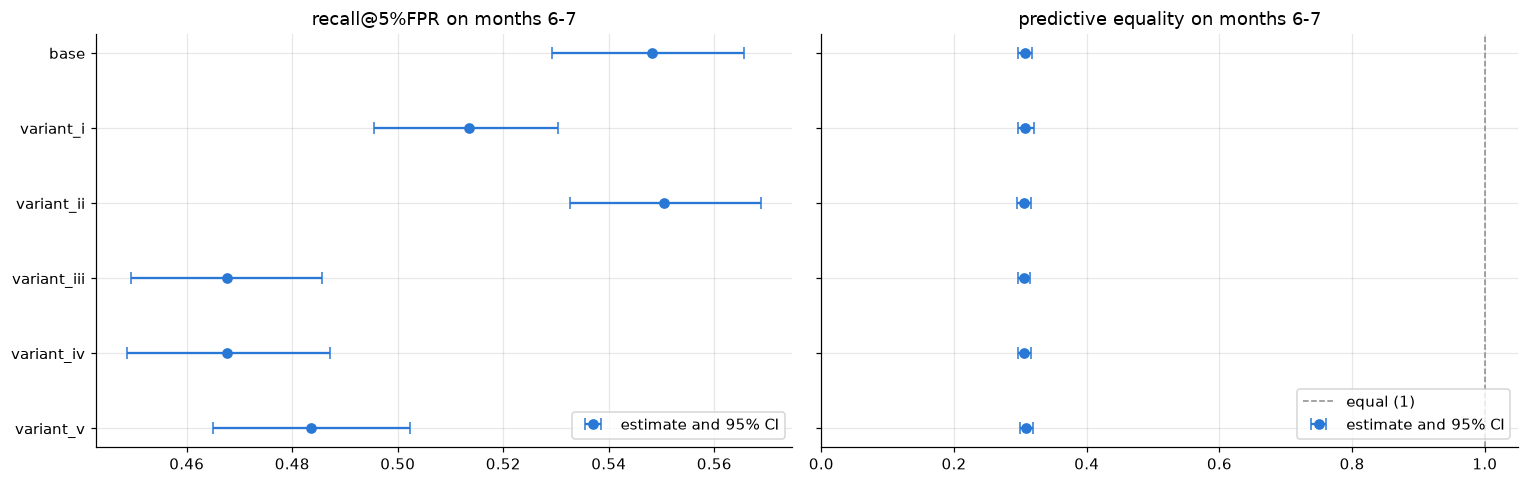

In [16]:
# Forest plot: the estimate and its 95% confidence interval on each dataset
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
positions = np.arange(len(DATASETS))[::-1]   # Base at the top

for ax, metric, reference, reference_label in [
    (axes[0], 'recall@5%FPR', None, None),
    (axes[1], 'predictive equality', 1, 'equal (1)'),
]:
    estimate = ci_table.xs(metric, level='metric').loc[DATASETS]
    ax.errorbar(estimate['estimate'], positions,
                xerr=[estimate['estimate'] - estimate['CI low'], estimate['CI high'] - estimate['estimate']],
                fmt='o', color=BLUE, ecolor=BLUE, capsize=4, markersize=6, label='estimate and 95% CI')
    if reference is not None:
        ax.axvline(reference, color=GREY, linestyle='--', linewidth=1, label=reference_label)
    ax.set_title(f'{metric} on months 6-7')
    ax.legend(loc='lower right')

axes[0].set_yticks(positions)
axes[0].set_yticklabels(DATASETS)
axes[1].set_xlim(0, 1.05)
plt.tight_layout()
plt.show()

**Findings**
- **The test set itself is a much bigger source of uncertainty than the seed.** On Base, recall at 5% FPR is 0.548 with a 95% CI of 0.529-0.566, so about ±0.018, against a seed standard deviation of only 0.002. ROC-AUC is 0.894 (0.888-0.899) and PR-AUC 0.197 (0.183-0.212).
- **Which differences between datasets are real?** The Base and Variant II intervals almost coincide (0.529-0.566 vs 0.533-0.569), so the model does equally well on both. Variants III-V (0.449-0.502) sit clearly below Base, so that drop is not chance. Variant I (0.496-0.530) only just touches Base's interval, so it is probably a little lower too.
- **The unfairness is not chance either.** Predictive equality is 0.307 on Base (0.296-0.318), and every dataset's interval lies between 0.295 and 0.321, far from 1. Genuine applicants aged 50+ are wrongly flagged about 3 times as often as younger ones on every dataset.
- **The frozen threshold flags slightly more than intended on Base.** Its FPR is 5.31% (5.22-5.41%), so the 5% target lies just outside the interval. On Variants II-V it is 8.3-8.4%, far above 5%.
- Variants III and IV have the same applications, yet their intervals differ slightly (by up to 0.002) because the resampling draws differ. That is the precision of the interval ends themselves.

## **6. Performance by Month**
Each month on its own: Base months 0-7 and the variants' months 5-7. For every month and seed we compute the fraud rate and the section-4 metrics, then average over the 5 seeds. The 95% confidence interval for the main metric (months 5-7) comes from the bootstrap of section 5 (1,000 resamples, averaged over seeds), run on each month separately.

How to read the Base months:
- **0-3, train (in-sample):** the model was trained on these applications, so its scores here are too optimistic.
- **4, validation:** used to choose the model and its settings, so also slightly optimistic.
- **5, threshold month:** the threshold was picked here, so the FPR at the threshold is 5% by construction.
- **6-7, test:** the honest results.

The two questions: does accuracy fall the further we get from the training months (5 to 6 to 7)? And does the frozen threshold keep flagging 5% of genuine applications, or does its FPR drift?

In [17]:
MONTH_ROLES = {0: 'train (in-sample)', 1: 'train (in-sample)', 2: 'train (in-sample)', 3: 'train (in-sample)',
               4: 'validation', 5: 'threshold month', 6: 'test', 7: 'test'}

rows = []
for (dataset, month), part in scores.groupby(['dataset', 'month'], observed=True):
    for seed in SEEDS:
        results = evaluate(part['y_true'], part[f'score_seed{seed}'], thresholds[seed], part['customer_age'])
        rows.append({'dataset': dataset, 'month': month, 'seed': seed,
                     'applications': len(part), 'fraud rate': part['y_true'].mean(), **results})
month_results = pd.DataFrame(rows)

monthly = month_results.drop(columns='seed').groupby(['dataset', 'month'], sort=False).mean()
monthly.insert(0, 'role', [MONTH_ROLES[m] for m in monthly.index.get_level_values('month')])
monthly['applications'] = monthly['applications'].astype(int)

# bootstrap 95% CI of the main metric on months 5-7 (the same code as section 5, one month at a time)
start = time.time()
month_parts = {key: part for key, part in
               scores[scores['month'].isin(VARIANT_MONTHS)].groupby(['dataset', 'month'], observed=True)}
for (dataset, month), resamples in zip(month_parts, bootstrap_parts(month_parts.values(), main_metric_only=True)):
    monthly.loc[(dataset, month), 'recall CI low'] = resamples['recall@5%FPR'].quantile(0.025)
    monthly.loc[(dataset, month), 'recall CI high'] = resamples['recall@5%FPR'].quantile(0.975)
print(f'Monthly bootstrap in {(time.time() - start) / 60:.1f} min')

monthly_columns = ['role', 'applications', 'fraud rate', 'recall@5%FPR', 'recall CI low', 'recall CI high',
                   'ROC-AUC', 'PR-AUC', 'FPR at threshold', 'recall at threshold', 'precision at threshold',
                   'FPR 50+', 'FPR under 50', 'predictive equality']
monthly = monthly[monthly_columns]
monthly.round(4)

Monthly bootstrap in 0.4 min


role  applications  fraud rate  recall@5%FPR  \
dataset     month                                                              
base        0      train (in-sample)        132440      0.0113        0.5519   
            1      train (in-sample)        127620      0.0094        0.6190   
            2      train (in-sample)        136979      0.0087        0.5992   
            3      train (in-sample)        150936      0.0092        0.6408   
            4             validation        127691      0.0114        0.5815   
            5        threshold month        119323      0.0118        0.5425   
            6                   test        108168      0.0134        0.5243   
            7                   test         96843      0.0147        0.5783   
variant_i   5        threshold month        119322      0.0118        0.5130   
            6                   test        108168      0.0134        0.4978   
            7                   test         96842      0.0147        0.5293   
variant_ii  5        threshold month        119324      0.0118        0.5586   
            6                   test        108168      0.0134        0.5448   
            7                   test         96842      0.0147        0.5581   
variant_iii 5        threshold month        147496      0.0091        0.4905   
            6                   test        136092      0.0123        0.4675   
            7                   test        105580      0.0093        0.4663   
variant_iv  5        threshold month        147496      0.0091        0.5577   
            6                   test        136092      0.0123        0.4675   
            7                   test        105580      0.0093        0.4663   
variant_v   5        threshold month        147496      0.0091        0.4730   
            6                   test        136092      0.0123        0.4898   
            7                   test        105580      0.0093        0.4724   

                   recall CI low  recall CI high  ROC-AUC  PR-AUC  \
dataset     month                                                   
base        0                NaN             NaN   0.9054  0.1851   
            1                NaN             NaN   0.9173  0.1683   
            2                NaN             NaN   0.9161  0.1710   
            3                NaN             NaN   0.9325  0.1872   
            4                NaN             NaN   0.9111  0.1869   
            5             0.5159          0.5672   0.8958  0.1898   
            6             0.4959          0.5500   0.8922  0.1796   
            7             0.5515          0.6020   0.8966  0.2196   
variant_i   5             0.4874          0.5386   0.8854  0.1741   
            6             0.4713          0.5236   0.8796  0.1615   
            7             0.5054          0.5537   0.8892  0.1965   
variant_ii  5             0.5339          0.5842   0.9013  0.1904   
            6             0.5184          0.5696   0.8992  0.2055   
            7             0.5342          0.5845   0.8953  0.2148   
variant_iii 5             0.4651          0.5176   0.8783  0.1234   
            6             0.4428          0.4909   0.8711  0.1410   
            7             0.4357          0.4956   0.8667  0.1058   
variant_iv  5             0.5310          0.5836   0.9001  0.1578   
            6             0.4435          0.4901   0.8711  0.1410   
            7             0.4373          0.4959   0.8667  0.1058   
variant_v   5             0.4462          0.5014   0.8737  0.1121   
            6             0.4670          0.5129   0.8725  0.1444   
            7             0.4408          0.5057   0.8720  0.1150   

                   FPR at threshold  recall at threshold  \
dataset     month                                          
base        0                0.0439               0.5236   
            1                0.0434               0.5843   
            2                0.0418               0.5628   
     

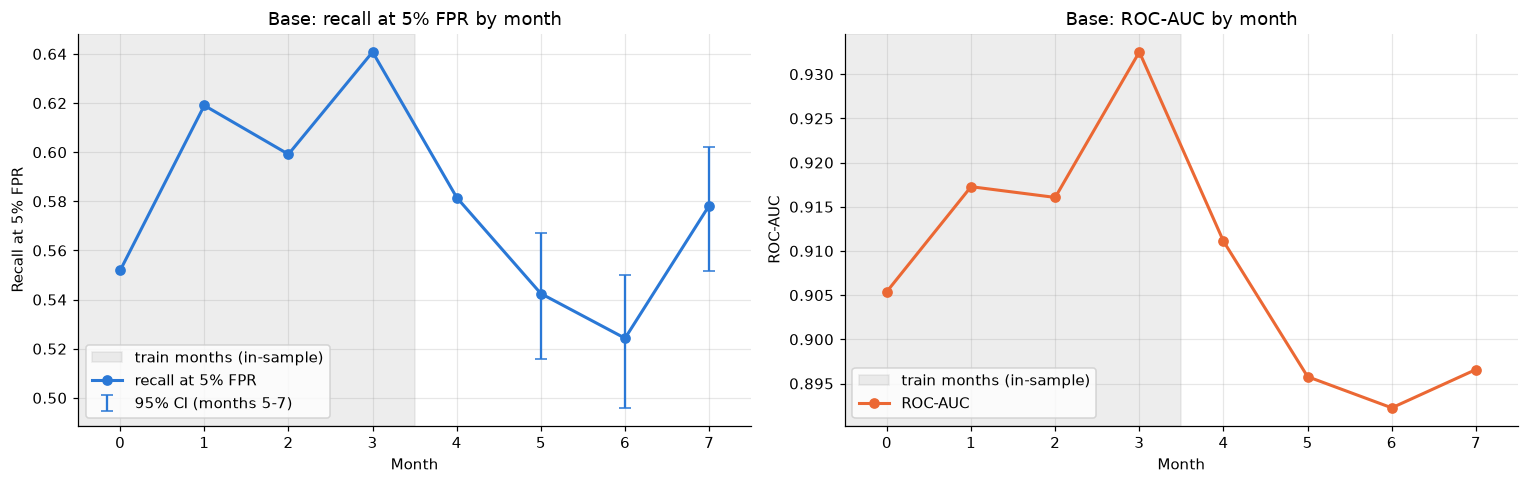

In [18]:
# (a) Base: ranking quality by month, with the training months shaded
base_monthly = monthly.loc['base']
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ax = axes[0]
ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.15, label='train months (in-sample)')
ax.plot(base_monthly.index, base_monthly['recall@5%FPR'], color=BLUE, marker='o', linewidth=2, label='recall at 5% FPR')
with_ci = base_monthly.dropna(subset=['recall CI low'])
ax.errorbar(with_ci.index, with_ci['recall@5%FPR'],
            yerr=[with_ci['recall@5%FPR'] - with_ci['recall CI low'], with_ci['recall CI high'] - with_ci['recall@5%FPR']],
            fmt='none', ecolor=BLUE, capsize=4, label='95% CI (months 5-7)')
ax.set_title('Base: recall at 5% FPR by month')
ax.set_ylabel('Recall at 5% FPR')
ax.legend(loc='lower left')

ax = axes[1]
ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.15, label='train months (in-sample)')
ax.plot(base_monthly.index, base_monthly['ROC-AUC'], color=ORANGE, marker='o', linewidth=2, label='ROC-AUC')
ax.set_title('Base: ROC-AUC by month')
ax.set_ylabel('ROC-AUC')
ax.legend(loc='lower left')

for ax in axes:
    ax.set_xlabel('Month')
    ax.set_xticks(BASE_MONTHS)
    ax.set_xlim(-0.5, 7.5)
plt.tight_layout()
plt.show()

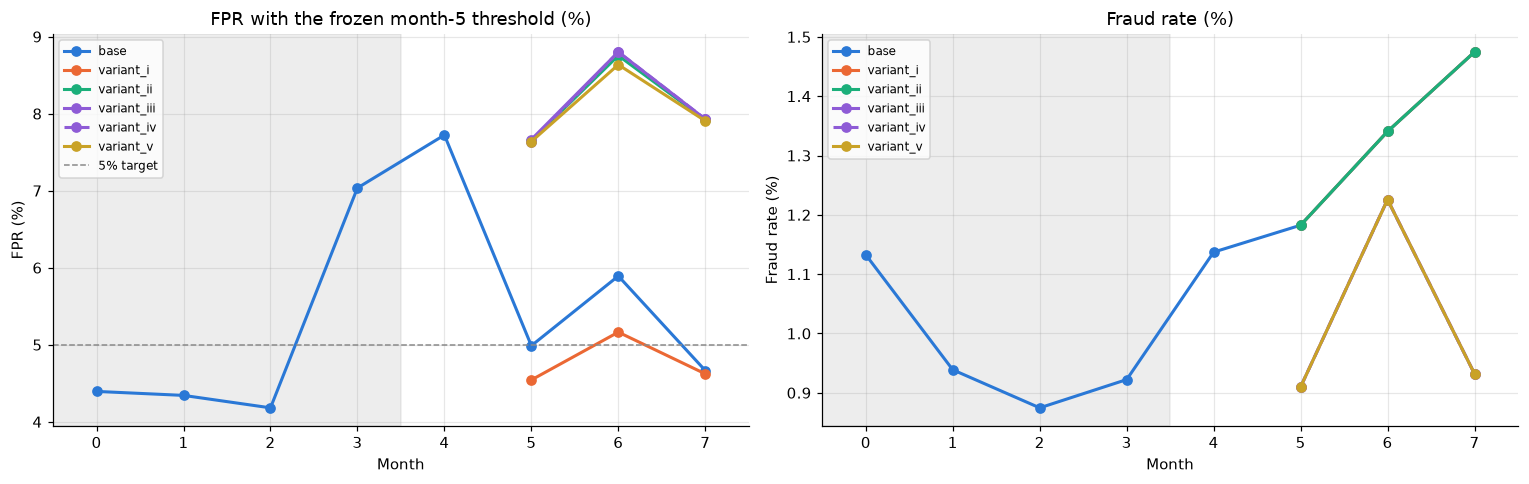

In [19]:
# (b) FPR with the frozen threshold and (c) fraud rate, by month, for every dataset
DATASET_COLOURS = {'base': BLUE, 'variant_i': ORANGE, 'variant_ii': GREEN,
                   'variant_iii': '#8e5bd6', 'variant_iv': '#8e5bd6', 'variant_v': '#c9a227'}
DATASET_STYLES = {'variant_iv': '--'}   # Variant IV's test months are the same applications as Variant III's

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for dataset in DATASETS:
    d = monthly.loc[dataset]
    style = dict(color=DATASET_COLOURS[dataset], linestyle=DATASET_STYLES.get(dataset, '-'), marker='o', linewidth=2,
                 label=dataset)
    axes[0].plot(d.index, d['FPR at threshold'] * 100, **style)
    axes[1].plot(d.index, d['fraud rate'] * 100, **style)

axes[0].axhline(TARGET_FPR * 100, color=GREY, linestyle='--', linewidth=1, label='5% target')
axes[0].set_title('FPR with the frozen month-5 threshold (%)')
axes[0].set_ylabel('FPR (%)')
axes[1].set_title('Fraud rate (%)')
axes[1].set_ylabel('Fraud rate (%)')
for ax in axes:
    ax.axvspan(-0.5, 3.5, color=GREY, alpha=0.15)
    ax.set_xlabel('Month')
    ax.set_xticks(BASE_MONTHS)
    ax.set_xlim(-0.5, 7.5)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Findings**

Does performance drop from month 5 to 6 to 7?
- **No steady drop.** On Base, recall at 5% FPR is 0.543 in month 5, 0.524 in month 6 and 0.578 in month 7, and ROC-AUC is 0.896, 0.892 and 0.897. Month 6 is the weakest month and month 7 the strongest, and their 95% CIs (0.496-0.550 and 0.552-0.602) just fail to overlap. So the months differ, but the model does not get steadily worse the further it is from its training months.
- **Variants I and II show the same dip in month 6** (I: 0.513, 0.498, 0.529; II: 0.559, 0.545, 0.558). Variants III and IV are flat and low on the test months (about 0.47 in both), and Variant V moves within 0.472-0.490.
- **Month-to-month swings are about as large as the differences between datasets.** Even on the training months, recall ranges from 0.552 (month 0) to 0.641 (month 3), so one month's result should not be read too precisely.
- **The training months look better, as expected.** Recall is 0.60-0.64 and ROC-AUC 0.916-0.933 on months 1-3, against 0.52-0.58 and 0.892-0.897 on the test months. Month 0 (recall 0.552) is the exception.
- **PR-AUC is highest in month 7 (0.220 on Base)** partly because there is more fraud to find: Base's fraud rate rises from 1.18% in month 5 to 1.34% and 1.47%. Variants I and II have the same fraud rate as Base in every month (their lines overlap), and Variants III-V share theirs (0.91%, 1.23%, 0.93%).

Does the frozen threshold's FPR drift?
- **It moves around, but does not drift in one direction.** On Base the FPR is 4.99% in month 5 (where the threshold was set), 5.89% in month 6 and 4.67% in month 7. Every dataset follows the same up-then-down shape: Variant I goes 4.54%, 5.16%, 4.62%, and Variants II-V go from 7.6-7.7% to 8.6-8.8% and back to 7.9%.
- **Variants II-V are already far above 5% in month 5**, so their high test FPR is not drift: it comes from their different mix of applicants, not from time.
- **The FPR also swings on the earlier Base months**: 4.2-4.4% on months 0-2, but 7.0% on month 3 and 7.7% on month 4. A threshold picked on one month is only roughly right for the next, so in practice it would need checking (and possibly resetting) every month.
- **Predictive equality stays at 0.29-0.32 on every month from 4 to 7** and on every dataset, so the age gap does not change over time. It is lower still (0.23-0.29) on the training months.